# AegisOT Smart Factory: Classification Reports

This notebook **only visualizes** the classification reports already produced by `04_classification_reports.py`.
No model is retrained, and no threshold, prediction or metric is changed.

**Task:** anomaly detection on smart factory sensor data (`0 = Normal`, `1 = Anomaly`, predicted with `score > threshold`).

**Models compared**

1. Autoencoder
2. Isolation Forest
3. LOF (Local Outlier Factor)
4. One-Class SVM (OCSVM)
5. Robust Baseline

**Splits:** Train, Validation, Test.

## 0. Setup and loading the reports

The notebook looks for `data/results/classification_reports/` in the current folder and then in each parent folder,
so it works whether Jupyter is started from the scripts folder or from the project root.

In [6]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

# Model folder name -> name shown in tables and charts
MODELS = {
    "autoencoder": "Autoencoder",
    "isolation_forest": "Isolation Forest",
    "lof": "LOF",
    "ocsvm": "OCSVM",
    "robust_baseline": "Robust Baseline",
}
SPLITS = ["train", "val", "test"]
SPLIT_NAMES = {"train": "Train", "val": "Validation", "test": "Test"}
CLASSES = ["Normal", "Anomaly"]
MODEL_ORDER = list(MODELS.values())

In [7]:
def find_reports_dir():
    """Search the current folder and its parents for data/results/classification_reports."""
    start = Path.cwd().resolve()
    for base in [start, *start.parents]:
        candidate = base / "data" / "results" / "classification_reports"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find data/results/classification_reports. "
        "Run 04_classification_reports.py first, or start Jupyter inside the project."
    )

REPORTS_DIR = find_reports_dir()
print("Reading reports from:", REPORTS_DIR)

Reading reports from: F:\college pdfs\AegisOT-AI-team\data\results\classification_reports


In [8]:
# Read all 15 JSON files (5 models x 3 splits)
reports, missing = {}, []

for key in MODELS:
    for split in SPLITS:
        path = REPORTS_DIR / key / f"{split}_report.json"
        if not path.exists():
            missing.append(str(path))
            continue
        with open(path, encoding="utf-8") as f:
            reports[(key, split)] = json.load(f)

if missing:
    raise FileNotFoundError("Missing report files:\n" + "\n".join(missing))

# Sanity check: file content matches the folder / file name
for (key, split), rep in reports.items():
    if rep.get("model_key") != key or rep.get("split") != split:
        warnings.warn(f"{key}/{split}: JSON says model_key={rep.get('model_key')}, split={rep.get('split')}")

print(f"Loaded {len(reports)} reports.")

Loaded 15 reports.


In [9]:
# One tidy table with every number we need, copied straight from the JSON files
rows = []
for (key, split), rep in reports.items():
    cr = rep["classification_report"]
    row = {
        "key": key, "model": MODELS[key], "split": split, "threshold": rep["threshold"],
        "accuracy": cr["accuracy"],
        "macro_precision": cr["macro avg"]["precision"],
        "macro_recall": cr["macro avg"]["recall"],
        "macro_f1": cr["macro avg"]["f1-score"],
    }
    for cls in CLASSES:
        for metric in ("precision", "recall", "f1-score", "support"):
            row[f"{cls}_{metric}"] = cr[cls][metric]
    rows.append(row)

metrics = pd.DataFrame(rows)
metrics.head(3)

,key,model,split,threshold,accuracy,macro_precision,macro_recall,macro_f1,Normal_precision,Normal_recall,Normal_f1-score,Normal_support,Anomaly_precision,Anomaly_recall,Anomaly_f1-score,Anomaly_support
0,autoencoder,Autoencoder,train,0.005,0.992,0.982,0.995,0.988,1.0,0.990,0.995,8350.0,0.965,1.000,0.982,2292.0
1,autoencoder,Autoencoder,val,0.005,0.995,0.989,0.996,0.993,1.0,0.994,0.997,2770.0,0.979,0.999,0.989,750.0
2,autoencoder,Autoencoder,test,0.005,0.988,0.972,0.992,0.981,1.0,0.985,0.992,2750.0,0.944,0.999,0.971,711.0


## 1. Overall Comparison

One table per split. The best value in each column is highlighted in green (ties are all highlighted).

In [10]:
OVERALL_COLS = {
    "accuracy": "Accuracy",
    "macro_precision": "Macro Precision",
    "macro_recall": "Macro Recall",
    "macro_f1": "Macro F1",
}

for split in SPLITS:
    table = (metrics[metrics["split"] == split]
             .set_index("model").loc[MODEL_ORDER, list(OVERALL_COLS)]
             .rename(columns=OVERALL_COLS))
    display(Markdown(f"### {SPLIT_NAMES[split]} split"))
    display(table.style.format("{:.3f}").highlight_max(axis=0, color="#dad4ed"))

### Train split

,Accuracy,Macro Precision,Macro Recall,Macro F1
model,,,,
Autoencoder,0.992,0.982,0.995,0.988
Isolation Forest,0.814,0.736,0.635,0.657
LOF,0.992,0.982,0.994,0.988
OCSVM,0.992,0.982,0.995,0.988
Robust Baseline,0.931,0.897,0.898,0.898


### Validation split

,Accuracy,Macro Precision,Macro Recall,Macro F1
model,,,,
Autoencoder,0.995,0.989,0.996,0.993
Isolation Forest,0.826,0.775,0.639,0.666
LOF,0.996,0.991,0.997,0.994
OCSVM,0.982,0.962,0.989,0.974
Robust Baseline,0.922,0.889,0.872,0.881


### Test split

,Accuracy,Macro Precision,Macro Recall,Macro F1
model,,,,
Autoencoder,0.988,0.972,0.992,0.981
Isolation Forest,0.821,0.746,0.616,0.638
LOF,0.983,0.961,0.989,0.974
OCSVM,0.969,0.935,0.981,0.955
Robust Baseline,0.950,0.935,0.907,0.920


## 2. Per-Model Classification Reports

For each model: precision, recall, F1-score and support for the **Normal** and **Anomaly** classes on every split.
The decision threshold stored in the report is shown above each table.

In [11]:
def report_table(key):
    rows = []
    for split in SPLITS:
        cr = reports[(key, split)]["classification_report"]
        for cls in CLASSES:
            rows.append({
                "Split": SPLIT_NAMES[split], "Class": cls,
                "Precision": cr[cls]["precision"], "Recall": cr[cls]["recall"],
                "F1-score": cr[cls]["f1-score"], "Support": cr[cls]["support"],
            })
    return pd.DataFrame(rows).set_index(["Split", "Class"])

fmt = {"Precision": "{:.3f}", "Recall": "{:.3f}", "F1-score": "{:.3f}", "Support": "{:.0f}"}

for key, name in MODELS.items():
    thresholds = {reports[(key, s)]["threshold"] for s in SPLITS}
    display(Markdown(f"### {name}"))
    print("Threshold:", ", ".join(f"{t:.6g}" for t in sorted(thresholds)))
    display(report_table(key).style.format(fmt))

### Autoencoder

Threshold: 0.00534547


### Isolation Forest

Threshold: 0.0258662


### LOF

Threshold: 1.82029


### OCSVM

Threshold: 0.000415385


### Robust Baseline

Threshold: 8


## 3. Visualizations

### 3.1 Accuracy and Macro F1 by model

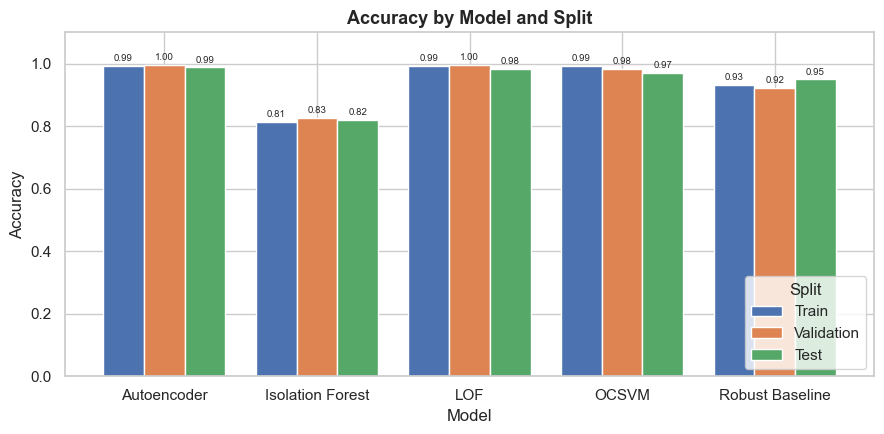

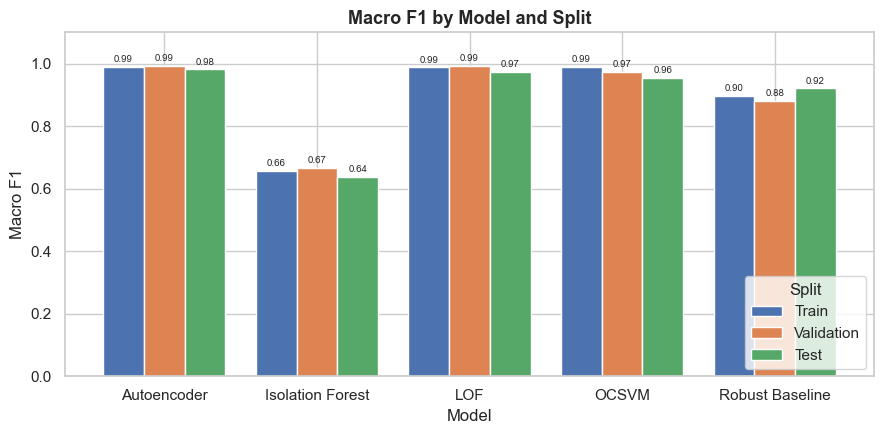

In [12]:
def grouped_bar(metric, title, ylabel):
    data = (metrics.pivot(index="model", columns="split", values=metric)
            .loc[MODEL_ORDER, SPLITS].rename(columns=SPLIT_NAMES))
    ax = data.plot.bar(figsize=(9, 4.5), width=0.8, edgecolor="white")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Model")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.1)
    ax.legend(title="Split", loc="lower right")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

grouped_bar("accuracy", "Accuracy by Model and Split", "Accuracy")
grouped_bar("macro_f1", "Macro F1 by Model and Split", "Macro F1")

### 3.2 Precision, Recall and F1-score by model

Shown for the **Test** split (change `PRF_SPLIT` to `"val"` or `"train"` to look at another split).
Both classes are shown so that missed anomalies (low Anomaly recall) and false alarms (low Anomaly precision) are easy to spot.

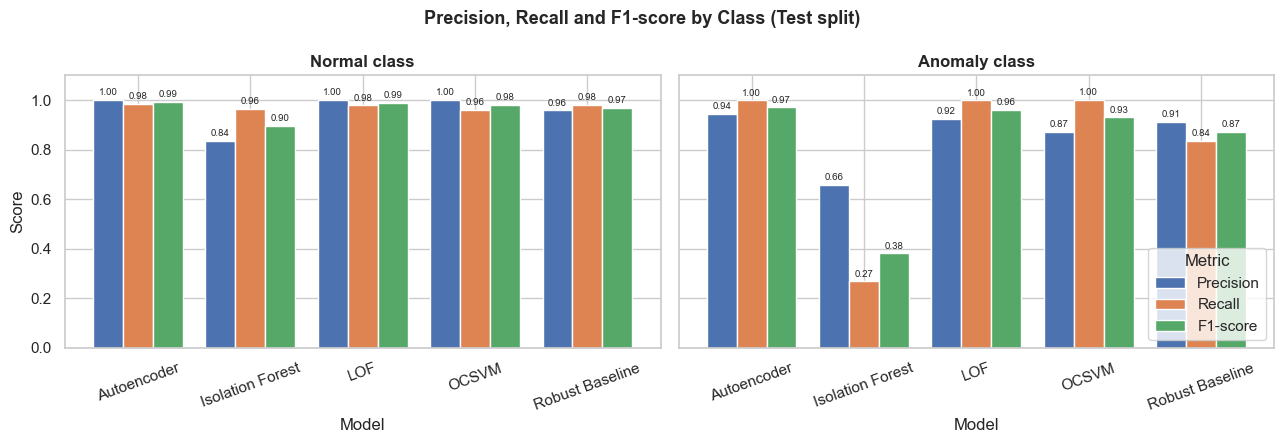

In [13]:
PRF_SPLIT = "test"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, cls in zip(axes, CLASSES):
    data = (metrics[metrics["split"] == PRF_SPLIT].set_index("model").loc[MODEL_ORDER,
            [f"{cls}_precision", f"{cls}_recall", f"{cls}_f1-score"]])
    data.columns = ["Precision", "Recall", "F1-score"]
    data.plot.bar(ax=ax, width=0.8, edgecolor="white", legend=False)
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=7, padding=2)
    ax.set_title(f"{cls} class", fontsize=12, fontweight="bold")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.1)
axes[1].legend(title="Metric", loc="lower right")
fig.suptitle(f"Precision, Recall and F1-score by Class ({SPLIT_NAMES[PRF_SPLIT]} split)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 3.3 Reconstructed confusion matrices (Test split)

The reports do not store confusion matrices, so they are **reconstructed** from the saved recall and support values:

- `TN = Recall(Normal) x Support(Normal)`  and  `FP = Support(Normal) - TN`
- `TP = Recall(Anomaly) x Support(Anomaly)`  and  `FN = Support(Anomaly) - TP`

Each result must be very close to a whole number before it is rounded. The counts are also cross-checked against the saved
precision and accuracy. If any check fails, a warning is raised and the matrix title is marked as **unreliable**.

In [14]:
INT_TOL = 1e-3    # max distance from a whole number before we call the reconstruction unreliable
CHECK_TOL = 1e-3  # max difference when re-computing precision / accuracy from the counts

def safe_div(a, b):
    return a / b if b else 0.0

def reconstruct_confusion(key, split):
    cr = reports[(key, split)]["classification_report"]
    n_norm, n_anom = cr["Normal"]["support"], cr["Anomaly"]["support"]
    tn_f = cr["Normal"]["recall"] * n_norm
    tp_f = cr["Anomaly"]["recall"] * n_anom

    problems = []
    for label, value in (("TN", tn_f), ("TP", tp_f), ("Normal support", n_norm), ("Anomaly support", n_anom)):
        if abs(value - round(value)) > INT_TOL:
            problems.append(f"{label} = {value:.4f} is not close to an integer")

    n_norm, n_anom = round(n_norm), round(n_anom)
    tn, tp = round(tn_f), round(tp_f)
    fp, fn = n_norm - tn, n_anom - tp

    # cross-check with the other numbers saved in the report
    checks = {
        "Anomaly precision": (safe_div(tp, tp + fp), cr["Anomaly"]["precision"]),
        "Normal precision": (safe_div(tn, tn + fn), cr["Normal"]["precision"]),
        "Accuracy": (safe_div(tp + tn, n_norm + n_anom), cr["accuracy"]),
    }
    for label, (rebuilt, saved) in checks.items():
        if abs(rebuilt - saved) > CHECK_TOL:
            problems.append(f"{label}: rebuilt {rebuilt:.4f} vs saved {saved:.4f}")

    matrix = pd.DataFrame([[tn, fp], [fn, tp]], index=CLASSES, columns=CLASSES)
    return matrix, problems

CM_SPLIT = "test"
matrices, unreliable = {}, {}
for key, name in MODELS.items():
    matrices[key], problems = reconstruct_confusion(key, CM_SPLIT)
    if problems:
        unreliable[key] = problems
        warnings.warn(f"{name} ({CM_SPLIT}): reconstruction is not reliable. " + "; ".join(problems))

if not unreliable:
    print("All reconstructions passed the integer and consistency checks.")

All reconstructions passed the integer and consistency checks.


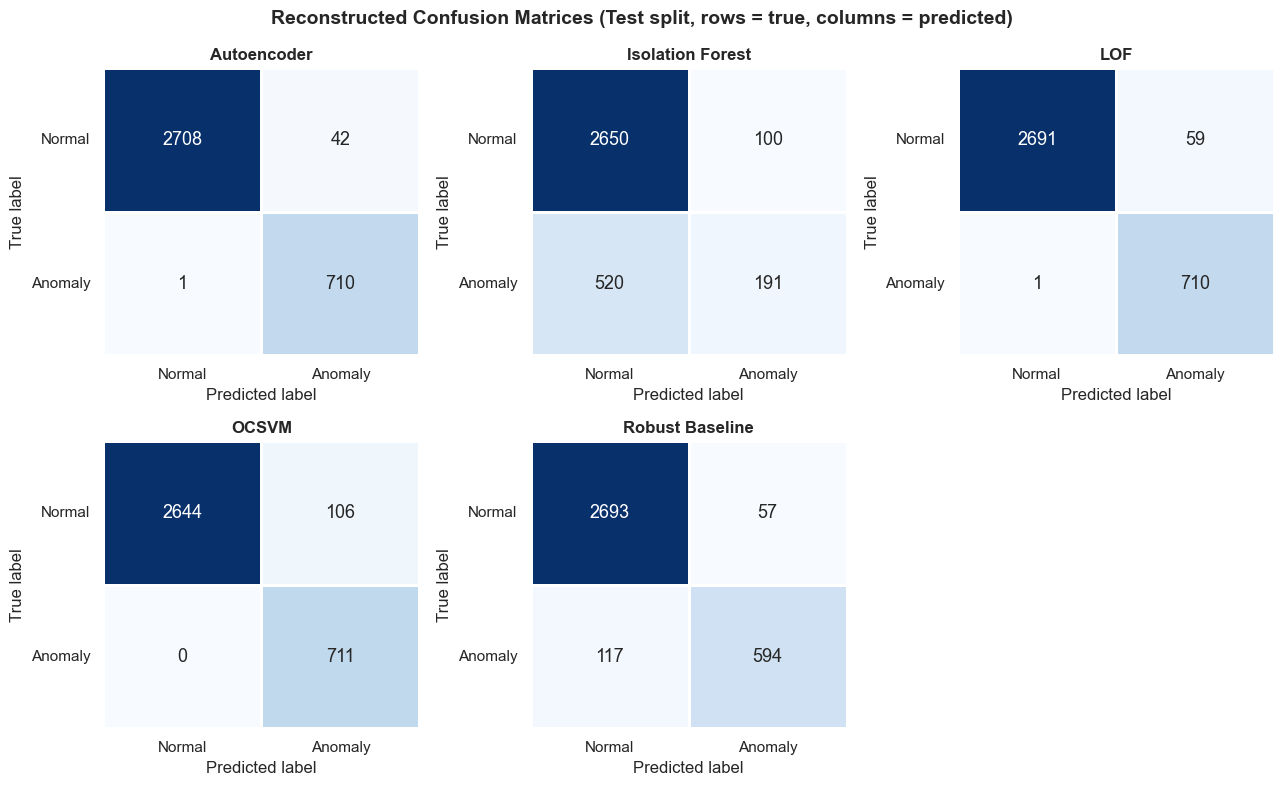

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
axes = axes.ravel()

for ax, (key, name) in zip(axes, MODELS.items()):
    sns.heatmap(matrices[key], annot=True, fmt="d", cmap="Blues", cbar=False,
                linewidths=1, linecolor="white", annot_kws={"size": 13}, ax=ax)
    ax.set_title(name + ("  (UNRELIABLE)" if key in unreliable else ""), fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="y", rotation=0)

for ax in axes[len(MODELS):]:
    ax.axis("off")   # hide the unused sixth panel

fig.suptitle(f"Reconstructed Confusion Matrices ({SPLIT_NAMES[CM_SPLIT]} split, rows = true, columns = predicted)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Short Summary

The table below is generated from the loaded reports. It lists, for each metric and split, the model with the highest value
(ties are listed together). Nothing here is hard-coded.

In [16]:
SUMMARY_METRICS = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro F1",
    "Anomaly_recall": "Anomaly recall",
    "Anomaly_precision": "Anomaly precision",
}

def best_models(metric, split):
    sub = metrics[metrics["split"] == split].set_index("model")[metric]
    top = sub.max()
    winners = [m for m in MODEL_ORDER if abs(sub[m] - top) < 1e-9]
    return f"{', '.join(winners)} ({top:.3f})"

summary = pd.DataFrame(
    {SPLIT_NAMES[s]: {label: best_models(col, s) for col, label in SUMMARY_METRICS.items()} for s in SPLITS}
)
summary.index.name = "Best model by"
display(summary)

,Train,Validation,Test
Best model by,,,
Accuracy,"Autoencoder, OCSVM (0.992)",LOF (0.996),Autoencoder (0.988)
Macro F1,OCSVM (0.988),LOF (0.994),Autoencoder (0.981)
Anomaly recall,OCSVM (1.000),OCSVM (1.000),OCSVM (1.000)
Anomaly precision,Autoencoder (0.965),LOF (0.982),Autoencoder (0.944)


### How to read these results

- **Best model depends on the metric.** Accuracy and Macro F1 summarize overall quality. Anomaly recall tells you how many faults were
  caught, and Anomaly precision tells you how many alarms were real. A model can lead on one and not on another, so compare the columns above
  before naming a "best" model.
- **Train metrics are not independent.** The models are fitted on the Normal rows of the training set, so Train scores say little about
  performance on unseen data. Validation and especially Test are the more informative splits.
- **Differences can be small.** Each split is one block-based partition of a single dataset, so small gaps between models should not be
  treated as decisive without further evidence.
- **Confusion matrices are reconstructed** from saved recall and support values and passed the checks shown in section 3.3.
- **Scope:** this notebook compares the saved reports only. It does not explain why a model behaves the way it does.

In [18]:
import mlflow
from mlflow import MlflowClient

client = MlflowClient()

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

print("\nExperiments:")
for exp in client.search_experiments():
    print(f"- {exp.name} | ID: {exp.experiment_id}")

print("\nRegistered Models:")
for model in client.search_registered_models():
    print(f"\n{model.name}")
    for version in model.latest_versions:
        print(
            f"  Version: {version.version} | "
            f"Run ID: {version.run_id} | "
            f"Status: {version.status}"
        )

2026/11/24 11:19:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/24 11:19:23 INFO mlflow.store.db.utils: Updating database tables


MLflow version: 3.18.0
Tracking URI: sqlite:///f:/college pdfs/AegisOT-AI-team/notebooks/mlflow.db

Experiments:
- Default | ID: 0

Registered Models:


In [19]:
import mlflow

print("Notebook Tracking URI:")
print(mlflow.get_tracking_uri())

Notebook Tracking URI:
sqlite:///f:/college pdfs/AegisOT-AI-team/notebooks/mlflow.db


In [20]:
from mlflow import MlflowClient

client = MlflowClient()

for exp in client.search_experiments():
    print(f"Name: {exp.name} | ID: {exp.experiment_id}")

Name: Default | ID: 0
